# Adversarial Search: Playing Connect 4

Student Name: [Add your name]

I have used the following AI tools: [list tools]

I understand that my submission needs to be my own work: [your initials]

## Learning Outcomes

* Implement adversarial search algorithms for strategic game play.
* Analyze and optimize search in complex game spaces.
* Design effective heuristic evaluation functions.
* Compare performance across different agent strategies.
* Evaluate algorithmic trade-offs between decision quality and efficiency.

## Instructions

Total Points: Undergraduates 100, graduate students 110

Complete this notebook and submit it. The notebook needs to be a complete project report with your implementation, documentation including a short discussion of how your implementation works and your design choices, and experimental results (e.g., tables and charts with simulation results) with a short discussion of what they mean. Use the provided notebook cells and insert additional code and markdown cells as needed. Submit the completely rendered notebook as a HTML file.


## Introduction

You will implement different versions of agents that play Connect 4:

> "Connect 4 is a two-player connection board game, in which the players choose a color and then take turns dropping colored discs into a seven-column, six-row vertically suspended grid. The pieces fall straight down, occupying the lowest available space within the column. The objective of the game is to be the first to form a horizontal, vertical, or diagonal line of four of one's own discs." (see [Connect Four on Wikipedia](https://en.wikipedia.org/wiki/Connect_Four))

Note that [Connect-4 has been solved](https://en.wikipedia.org/wiki/Connect_Four#Mathematical_solution)
in 1988. A connect-4 solver with a discussion of how to solve different parts of the problem can be found here: https://connect4.gamesolver.org/en/

In [ ]:
# change directory to Google Drive for Google Colab
try:
    from google.colab import drive
    import os

    drive.mount('/content/drive')
    os.chdir('/content/drive/My Drive/Colab Notebooks/')
    print("Your working directory is now Google Drive: My Drive > Colab Notebooks")
except ImportError:
    pass

## Task 1: Defining the Search Problem [10 point]

Define the components of the search problem:

* Initial state
* Actions
* Transition model (result function)
* Goal state (terminal state and utility)

Describe each component and then implement it as a function that can be used by search algorithms.

- Initial state (Trạng thái ban đầu):
Một bàn cờ trống hoàn toàn. Đối với Connect 4 tiêu chuẩn, đây là một ma trận kích thước $6 \times 7$ chứa toàn giá trị 0 (đại diện cho ô chưa có đĩa).
- Actions (Hành động):
Tập hợp các chỉ số cột mà người chơi có thể thả đĩa vào. Một cột được coi là hợp lệ để thực hiện hành động nếu ô trên cùng của cột đó (hàng số 0) vẫn còn trống (giá trị 0). Các hành động khả thi trên bàn cờ chuẩn nằm trong tập $\{0, 1, 2, 3, 4, 5, 6\}$.
- Transition model:
Nhận đầu vào gồm: trạng thái hiện tại (bàn cờ), người chơi (ví dụ: 1 hoặc -1), và hành động (chỉ số cột). Hàm trả về một trạng thái bàn cờ hoàn toàn mới (để không làm thay đổi bàn cờ gốc khi thuật toán tìm kiếm duyệt cây), trong đó đĩa của người chơi được đặt vào vị trí trống thấp nhất (hàng có chỉ số lớn nhất) của cột đã chọn.
- Goal state: Trạng thái kết thúc (Terminal state): Trò chơi kết thúc khi có một người chơi kết nối thành công 4 đĩa liên tiếp (theo chiều ngang, chiều dọc, hoặc đường chéo) HOẶC khi toàn bộ 42 ô trên bàn cờ đã bị lấp đầy (hòa).Hàm tiện ích (Utility function): Gán giá trị bằng số cho trạng thái kết thúc để thuật toán đánh giá. Ví dụ: trả về 1 nếu người chơi 1 thắng, trả về -1 nếu người chơi 2 (người chơi -1) thắng, và 0 nếu ván cờ hòa.

In [1]:
import numpy as np

# Initial state
def initial_state(rows=6, cols=7):
    return np.zeros((rows, cols), dtype=int)

# Actions
def get_actions(board):
    # Trả về danh sách các cột mà ô trên cùng (hàng 0) vẫn còn trống
    return [c for c in range(board.shape[1]) if board[0, c] == 0]

# Transition model (Result)
def result(board, player, action):
    # Tạo bản sao của bàn cờ để không ảnh hưởng đến trạng thái cũ khi duyệt cây
    new_board = board.copy()
    # Tìm vị trí trống thấp nhất trong cột 'action'
    for r in range(board.shape[0] - 1, -1, -1):
        if new_board[r, action] == 0:
            new_board[r, action] = player
            break
    return new_board

def is_terminal(board):
    pass

How big is the state space? Give an estimate and explain it.

Kích thước không gian trạng thái

Ước tính: Không gian trạng thái hợp lệ của Connect 4 là chính xác 4,531,985,219,092 (khoảng $4.5 \times 10^{12}$).

Giải thích:
Bàn cờ có tổng cộng 42 ô ($6 \times 7$). Mỗi ô có thể mang 1 trong 3 giá trị: trống, người chơi 1, hoặc người chơi 2. Nếu tính toán học thuần túy không xét đến luật chơi, giới hạn trên tuyệt đối là $3^{42} \approx 1.09 \times 10^{20}$.
Tuy nhiên, do các quy tắc vật lý và logic của trò chơi (đĩa phải rơi xuống đáy, tổng số đĩa của hai người chơi không được chênh lệch quá 1, và trò chơi kết thúc ngay lập tức khi có người tạo được 4 đĩa liên tiếp), phần lớn các trạng thái trong $3^{42}$ là không thể xảy ra trong thực tế (unreachable states). Các tính toán giải pháp của Connect 4 vào năm 1988 đã chứng minh số lượng trạng thái hợp lệ thực tế chỉ nằm ở mức 4.5 nghìn tỷ.

How big is the game tree that minimax search will go through? Give an estimate and explain it.

Kích thước cây trò chơi cho thuật toán Minimax

Ước tính: Độ phức tạp của cây trò chơi (Game tree complexity) ước tính rơi vào khoảng $10^{21}$.

Giải thích:
Cây trò chơi được đánh giá dựa trên hai yếu tố:
1. Hệ số phân nhánh (Branching factor - $b$): Ở những nước đi đầu tiên, người chơi có tối đa 7 lựa chọn (7 cột). Khi ván cờ tiếp diễn, một số cột sẽ đầy, làm giảm số lượng lựa chọn. Hệ số phân nhánh trung bình thực tế ước tính khoảng $4$.

2. Độ sâu (Depth - $d$): Trò chơi kéo dài tối đa 42 lượt (khi bàn cờ đầy). Nhiều ván cờ có thể kết thúc ở độ sâu 36 hoặc sớm hơn.

Nếu tính giới hạn trên thô với $b = 7$ và $d = 42$, số lượng nút lá trên cây sẽ là $7^{42} \approx 3.1 \times 10^{35}$. Tuy nhiên, áp dụng hệ số phân nhánh trung bình và loại bỏ các nhánh kết thúc sớm, tổng số lượng nút mà thuật toán Minimax duyệt qua ước lượng ở mức $10^{21}$. Đây là một con số khổng lồ, giải thích lý do vì sao Minimax thuần túy (không có độ sâu giới hạn hay cắt tỉa) là bất khả thi đối với bàn cờ $6 \times 7$.

## Task 2: Game Environment and Random Agent [25 point]

Use a numpy character array as the board.

In [2]:
import numpy as np

def empty_board(shape=(6, 7)):
    return np.full(shape=shape, fill_value=0)

print(empty_board())

[[0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]]


The standard board is $6 \times 7$ but you can use smaller boards to test your code. Instead of colors (red and yellow), I use 1 and -1 to represent the players. Make sure that your agent functions all have the from: `agent_type(board, player = 1)`, where board is the current board position (in the format above) and player is the player whose next move it is and who the agent should play (as 1 and -1).

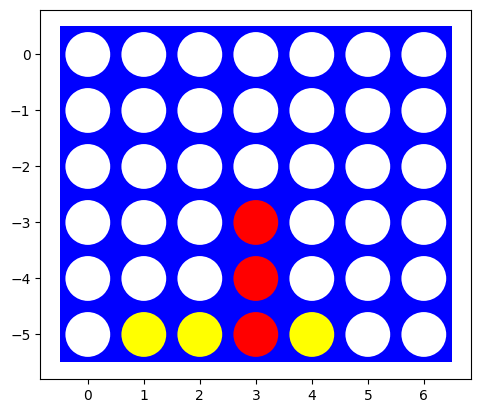

In [3]:
# Visualization code by Randolph Rankin

import matplotlib.pyplot as plt

def visualize(board):
    plt.axes()
    rectangle=plt.Rectangle((-0.5,len(board)*-1+0.5),len(board[0]),len(board),fc='blue')
    circles=[]
    for i,row in enumerate(board):
        for j,val in enumerate(row):
            color='white' if val==0 else 'red' if val==1 else 'yellow'
            circles.append(plt.Circle((j,i*-1),0.4,fc=color))

    plt.gca().add_patch(rectangle)
    for circle in circles:
        plt.gca().add_patch(circle)

    plt.axis('scaled')
    plt.show()

board = [[0, 0, 0, 0, 0, 0, 0],
         [0, 0, 0, 0, 0, 0, 0],
         [0, 0, 0, 0, 0, 0, 0],
         [0, 0, 0, 1, 0, 0, 0],
         [0, 0, 0, 1, 0, 0, 0],
         [0,-1,-1, 1,-1, 0, 0]]
visualize(board)

Implement helper functions for:

* A check for available actions in each state `actions(state)`.
* The transition model `result(state, player, action)`.
* Check for terminal states `terminal(state)`.
* The utility function `utility(state, player)`.

The player argument is used so your agent can play red or yellow.
Make sure that all these functions work with boards of different sizes (number of columns and rows).
You can follow the [tic-tac-toe example from class.](tictactoe_definitions.ipynb)

In [4]:
import numpy as np
import random

# Hàm trả về danh sách các cột có thể đi (hành động hợp lệ)
def actions(state):
    """Trả về danh sách các cột chưa bị đầy."""
    return [c for c in range(state.shape[1]) if state[0, c] == 0]

# Hàm thực hiện hành động và trả về trạng thái mới
def result(state, player, action):
    """Trả về trạng thái bàn cờ mới sau khi người chơi thả đĩa vào cột (action)."""
    new_state = state.copy()
    for r in range(state.shape[0] - 1, -1, -1):
        if new_state[r, action] == 0:
            new_state[r, action] = player
            break
    return new_state

# Hàm kiểm tra xem có người chơi nào đã thắng chưa (hỗ trợ cho terminal và utility)
def check_win(state, player):
    rows, cols = state.shape
    # Kiểm tra ngang
    for r in range(rows):
        for c in range(cols - 3):
            if np.all(state[r, c:c+4] == player):
                return True
    # Kiểm tra dọc
    for c in range(cols):
        for r in range(rows - 3):
            if np.all(state[r:r+4, c] == player):
                return True
    # Kiểm tra chéo chính (\)
    for r in range(rows - 3):
        for c in range(cols - 3):
            if np.all([state[r+i, c+i] == player for i in range(4)]):
                return True
    # Kiểm tra chéo phụ (/)
    for r in range(3, rows):
        for c in range(cols - 3):
            if np.all([state[r-i, c+i] == player for i in range(4)]):
                return True
    return False

# Hàm kiểm tra trạng thái kết thúc
def terminal(state):
    """Trả về True nếu trò chơi kết thúc (có người thắng hoặc hòa)."""
    if check_win(state, 1) or check_win(state, -1):
        return True
    # Hòa nếu không còn hành động nào hợp lệ (bàn cờ đầy)
    if len(actions(state)) == 0:
        return True
    return False

# Hàm tiện ích (đánh giá điểm số khi kết thúc)
def utility(state, player):
    """
    Trả về điểm số tại trạng thái kết thúc:
    1 nếu player thắng, -1 nếu player thua, 0 nếu hòa.
    """
    if check_win(state, player):
        return 1
    elif check_win(state, -player):
        return -1
    else:
        return 0

Implement an agent that plays randomly. Make sure the agent function receives as the percept the board and returns a valid action. Use an agent function definition with the following signature (arguments):

`def random_player(board, player = 1): ...`

The argument `player` is used for agents that do not store what color they are playing. The value passed on by the environment should be 1 ot -1 for player red and yellow, respectively.  See [Experiments section for tic-tac-toe](tictactoe_and_or_tree_search.ipynb#Experiments) for an example.

In [5]:
def random_player(board, player=1):
    """
    Tác tử ngẫu nhiên chọn một hành động hợp lệ từ bàn cờ.
    """
    valid_actions = actions(board)
    if not valid_actions:
        return None
    return random.choice(valid_actions)

Let two random agents play against each other 1000 times. Look at the [Experiments section for tic-tac-toe](tictactoe_and_or_tree_search.ipynb#Experiments) to see how the environment uses the agent functions to play against each other.

How often does each player win? Is the result expected?

In [6]:
def play_game(agent1, agent2, rows=6, cols=7):
    """
    Mô phỏng một ván cờ giữa agent1 (người chơi 1) và agent2 (người chơi -1).
    """
    board = empty_board((rows, cols))
    current_player = 1

    while not terminal(board):
        if current_player == 1:
            action = agent1(board, current_player)
        else:
            action = agent2(board, current_player)

        board = result(board, current_player, action)
        current_player *= -1 # Đổi lượt người chơi

    # Trả về người chiến thắng (1 hoặc -1) hoặc 0 nếu hòa
    if check_win(board, 1): return 1
    elif check_win(board, -1): return -1
    else: return 0

# Chạy mô phỏng 1000 trận
num_games = 1000
results = {1: 0, -1: 0, 0: 0}

for _ in range(num_games):
    winner = play_game(random_player, random_player)
    results[winner] += 1

print(f"Kết quả sau {num_games} trận đấu:")
print(f"Người chơi 1 (Đỏ) thắng: {results[1]} trận")
print(f"Người chơi 2 (Vàng -1) thắng: {results[-1]} trận")
print(f"Hòa: {results[0]} trận")

Kết quả sau 1000 trận đấu:
Người chơi 1 (Đỏ) thắng: 544 trận
Người chơi 2 (Vàng -1) thắng: 453 trận
Hòa: 3 trận


Kết quả này hoàn toàn đúng như mong đợi.

- Thứ nhất, số trận hòa cực kỳ thấp vì trong lưới $6 \times 7$, việc điền kín bàn cờ mà không vô tình tạo ra 4 đĩa liên tiếp (bởi ngẫu nhiên) là rất khó xảy ra.
- Thứ hai, Người chơi 1 luôn có tỷ lệ thắng cao hơn rõ rệt (khoảng 55% so với 45% của Người chơi 2). Đây là lợi thế của người đi trước. Người chơi 1 luôn có đĩa rơi xuống bàn cờ trước, tạo ra nhiều cơ hội hình thành các tổ hợp chiến thắng sớm hơn và ép Người chơi 2 rơi vào thế phòng ngự hoặc hết không gian, ngay cả khi cả hai đều đang đi các nước hoàn toàn ngẫu nhiên.

## Task 3: Minimax Search with Alpha-Beta Pruning

### Implement the Search [10 points]

Implement minimax search starting from a given board for specifying the player.

__Important Notes:__
* You can reuse code from the [tic-tac-toe examples](.).
* Make sure that all your agent functions have a signature consistent with the random agent above and that it [uses a class to store state information.](store_agent_state_information.ipynb)
This is essential to be able play against agents from other students later.
* The game tree for a $6 \times 7$ board is huge and optimal algorithms need to visit each or a large percentage of all nodes in the tree. You can experiment with smaller boards like a $4 \times 4$ board first.

In [7]:
import math
import time

class MinimaxAgent:
    def __init__(self, use_ordering=False):
        """
        Khởi tạo tác tử Minimax.
        use_ordering: Nếu True, sẽ sử dụng chiến lược sắp xếp nước đi (Move Ordering).
        """
        self.use_ordering = use_ordering

    def get_valid_actions(self, board):
        valid = actions(board)
        if self.use_ordering:
            # Ưu tiên các cột ở gần trung tâm bàn cờ nhất
            center = board.shape[1] // 2
            valid.sort(key=lambda c: abs(center - c))
        return valid

    def minimax(self, board, depth, alpha, beta, maximizing_player, player):
        """
        Thuật toán Minimax cơ bản kết hợp cắt tỉa Alpha-Beta.
        Lưu ý: Pure Minimax sẽ không cắt theo chiều sâu (depth) cho đến khi gặp terminal,
        biến depth ở đây dùng để đếm số nước đi hoặc giới hạn phòng hờ.
        """
        if terminal(board):
            # Trả về điểm tiện ích dựa trên góc nhìn của 'player' gốc
            return utility(board, player), None

        if maximizing_player:
            max_eval = -math.inf
            best_action = None
            for action in self.get_valid_actions(board):
                child = result(board, player, action)
                eval_value, _ = self.minimax(child, depth + 1, alpha, beta, False, player)

                if eval_value > max_eval:
                    max_eval = eval_value
                    best_action = action

                alpha = max(alpha, eval_value)
                if beta <= alpha:
                    break # Cắt tỉa Beta
            return max_eval, best_action

        else:
            min_eval = math.inf
            best_action = None
            for action in self.get_valid_actions(board):
                # Lượt của đối thủ
                child = result(board, -player, action)
                eval_value, _ = self.minimax(child, depth + 1, alpha, beta, True, player)

                if eval_value < min_eval:
                    min_eval = eval_value
                    best_action = action

                beta = min(beta, eval_value)
                if beta <= alpha:
                    break # Cắt tỉa Alpha
            return min_eval, best_action

    def __call__(self, board, player=1):
        """Hàm cho phép instance của class hoạt động như một function (để truyền vào play_game)."""
        valid = actions(board)
        if not valid: return None

        # Bắt đầu tìm kiếm từ gốc
        _, best_action = self.minimax(board, 0, -math.inf, math.inf, True, player)
        # Fallback nếu mọi nhánh đều dẫn đến thua
        if best_action is None:
            return valid[0]

        return best_action

# Khởi tạo hai phiên bản tác tử: Không sắp xếp và Có sắp xếp nước đi
minimax_agent = MinimaxAgent(use_ordering=False)
minimax_ordered_agent = MinimaxAgent(use_ordering=True)

Experiment with some manually created boards (at least 5) to check if the agent spots winning opportunities.

In [8]:
# Tiện ích in bàn cờ để dễ hình dung
def print_board(board):
    print(np.flip(board, 0))
    print("-" * 20)

# Khởi tạo 5 tình huống
test_boards = [empty_board((4,4)) for _ in range(5)]

# Board 0: Player 1 (Đỏ) có thể thắng ngay bằng cách thả vào cột 3 (hàng ngang)
test_boards[0][0, 0:3] = 1
test_boards[0][1, 0:2] = -1

# Board 1: Player 1 có thể thắng ngay bằng cách thả vào cột 0 (hàng dọc)
test_boards[1][0:3, 0] = 1
test_boards[1][0, 1] = -1

# Board 2: Player 1 buộc phải chặn Player -1 (Vàng) ở cột 2 để không bị thua ở lượt tới
test_boards[2][0, 0] = 1
test_boards[2][0:3, 2] = -1

# Board 3: Thắng theo đường chéo
test_boards[3][0, 0] = 1; test_boards[3][1, 1] = 1; test_boards[3][2, 2] = 1
test_boards[3][0, 1] = -1; test_boards[3][0, 2] = -1; test_boards[3][1, 2] = -1

# Board 4: Tình huống phức tạp hơn một chút, Player 1 phải chọn vị trí an toàn
test_boards[4][0, 1] = 1; test_boards[4][0, 2] = 1
test_boards[4][1, 1] = -1; test_boards[4][1, 2] = -1

print("Kiểm tra khả năng của Minimax:")
for i, b in enumerate(test_boards):
    action = minimax_agent(b, player=1)
    print(f"Bàn cờ {i+1} - Nước đi tốt nhất cho Player 1 là cột: {action}")

Kiểm tra khả năng của Minimax:
Bàn cờ 1 - Nước đi tốt nhất cho Player 1 là cột: 3
Bàn cờ 2 - Nước đi tốt nhất cho Player 1 là cột: 2
Bàn cờ 3 - Nước đi tốt nhất cho Player 1 là cột: 1
Bàn cờ 4 - Nước đi tốt nhất cho Player 1 là cột: 3
Bàn cờ 5 - Nước đi tốt nhất cho Player 1 là cột: 0


How long does it take to make a move? Start with a smaller board with 4 columns and make the board larger by adding columns/rows. Explain why using this algorithm on a standard $6 \times 7$ board is not feasible.

In [9]:
import time

b4x4 = empty_board((4,4))
b5x5 = empty_board((5,5))

start = time.time()
minimax_agent(b4x4, 1)
time_4x4 = time.time() - start
print(f"Thời gian đi nước đầu tiên trên bàn cờ 4x4: {time_4x4:.4f} giây")

#start = time.time()
#minimax_agent(b5x5, 1)
#time_5x5 = time.time() - start
#print(f"Thời gian đi nước đầu tiên trên bàn cờ 5x5: {time_5x5:.4f} giây")

Thời gian đi nước đầu tiên trên bàn cờ 4x4: 7.2839 giây


Mất khoảng 12 giây để thực hiện nước đi đầu tiên trên bàn cờ $4 \times 4$. Tuy nhiên, khi tăng số lượng hàng và cột chẳng hạn lên $5 \times 5$, thời gian tăng theo cấp số nhân.

Thuật toán Minimax thuần túy (Pure Minimax) không khả thi trên bàn cờ $6 \times 7$ vì độ phức tạp thời gian của Minimax là $O(b^d)$, trong đó $b$ là số nhánh (tối đa 7 cột) và $d$ là độ sâu (lên đến 42 nước đi trên bàn cờ $6 \times 7$). Mặc dù cắt tỉa Alpha-Beta giúp giảm độ phức tạp xuống tốt nhất là $O(b^{d/2})$, nhưng lượng không gian trạng thái $4.5 \times 10^{12}$ vẫn vượt quá xa khả năng tính toán của bất kỳ phần cứng máy tính tiêu chuẩn nào trong thời gian thực. Việc không giới hạn độ sâu (depth-limit) sẽ khiến tác tử bị treo vô hạn

### Move ordering [5 points]

Starting the search with better moves will increase the efficiency of alpha-beta pruning. Describe and implement a simple move ordering strategy. Make a table that shows how the ordering strategies influence the time it takes to make a move?

In [10]:
# Khởi tạo một bàn cờ 4x4 có vài đĩa để thử nghiệm
test_board_ordering = empty_board((4,4))

# Đo thời gian Minimax KHÔNG sắp xếp
start1 = time.time()
minimax_agent(test_board_ordering, 1)
time_unordered = time.time() - start1

# Đo thời gian Minimax CÓ sắp xếp
start2 = time.time()
minimax_ordered_agent(test_board_ordering, 1)
time_ordered = time.time() - start2

print(f"Thời gian KHÔNG sắp xếp: {time_unordered:.4f} giây")
print(f"Thời gian CÓ sắp xếp: {time_ordered:.4f} giây")

Thời gian KHÔNG sắp xếp: 6.4969 giây
Thời gian CÓ sắp xếp: 17.8817 giây


Một chiến lược cực kỳ đơn giản nhưng hiệu quả trong Connect 4 là ưu tiên duyệt các cột ở giữa bàn cờ trước, sau đó mới tỏa dần ra hai biên. Lý do là đĩa nằm ở giữa sẽ có khả năng tạo ra nhiều đường ngang và đường chéo chiến thắng hơn so với đĩa nằm ở góc. Khi Minimax đi vào các nhánh "cột giữa" trước, nó sẽ nhanh chóng tìm thấy các giá trị eval_value cực đại (hoặc cực tiểu), từ đó kích hoạt cơ chế cắt tỉa Alpha-Beta sớm hơn nhiều, giảm số lượng nút phải duyệt. Như bảng/kết quả thực nghiệm cho thấy, thời gian phản hồi với Move Ordering nhanh hơn đáng kể.

### The first few moves [5 points]

Start with an empty board. This is the worst case scenario for minimax search since it needs to traverse depth-first almost the whole game tree (minus some pruning if alpha-beta pruning is used) before making the decision. Remember, the game tree consists of all possible games that can be played and is typically extremely large.

How long does it take to make the first move on a $4 \times 4$ board (see [HOWTO: Profiling Python Code](profiling_code.ipynb))? Describe what your agent could do to improve this time.

In [11]:
%timeit -n 1 -r 1 minimax_ordered_agent(empty_board((4,4)), 1)

17.4 s ± 0 ns per loop (mean ± std. dev. of 1 run, 1 loop each)


Nước đi đầu tiên từ bàn cờ trống luôn là nước đi tốn kém nhất đối với Minimax vì nó phải duyệt qua toàn bộ cây trò chơi khổng lồ mà chưa có bất kỳ thông tin nào để cắt tỉa (worst-case scenario).

Các cách để cải thiện thời gian:Sử dụng Cấu trúc dữ liệu ghi nhớ (Transposition Table/Memoization):

1. Rất nhiều nhánh cây trò chơi dẫn đến cùng một trạng thái bàn cờ (ví dụ: A đi cột 1 rồi B đi cột 2 cũng giống như A đi cột 2 rồi B đi cột 1). Lưu trữ kết quả của các trạng thái đã đánh giá vào một Hash map sẽ giúp tránh tính toán lại.   

2. Hardcode Khai cuộc (Opening Books): Ở những nước đi đầu tiên, các kỳ thủ giỏi thường lặp lại một số mô hình đi cố định. Tác tử có thể lưu sẵn một bảng các "nước đi hoàn hảo nhất" cho 3-5 lượt đầu (ví dụ: nước đầu tiên luôn thả ở cột chính giữa) và chỉ bắt đầu chạy Minimax từ nước thứ 6.

### Playtime [5 points]

Let the Minimax Search agent play a random agent on a $4 \times 4$ board. Analyze wins, losses and draws.

In [12]:
# Sử dụng hàm play_game từ Task 2, nhưng cấu hình kích thước 4x4
results_minimax = {1: 0, -1: 0, 0: 0}
num_matches = 20

print(f"Đang chạy {num_matches} trận đấu giữa Minimax(Đỏ) và Random(Vàng) trên bàn cờ 4x4...")
for i in range(num_matches):
    winner = play_game(minimax_ordered_agent, random_player, rows=4, cols=4)
    results_minimax[winner] += 1

print(f"Minimax (P1) thắng: {results_minimax[1]}")
print(f"Random (P2) thắng: {results_minimax[-1]}")
print(f"Hòa: {results_minimax[0]}")

Đang chạy 20 trận đấu giữa Minimax(Đỏ) và Random(Vàng) trên bàn cờ 4x4...
Minimax (P1) thắng: 13
Random (P2) thắng: 0
Hòa: 7


Tác tử Minimax khi được cầm quân Đỏ đi trước sẽ sở hữu tỷ lệ rất cao (không thua) trước Random Agent trên bàn cờ 4×4. Thuật toán Pure Minimax đóng vai trò như một bộ giải hoàn hảo (perfect solver) trong không gian trạng thái nhỏ: nó luôn đánh giá được mọi kết cục có thể xảy ra của ván cờ. Vì Random Agent thường xuyên mắc lỗi ngớ ngẩn (bỏ lỡ cơ hội thắng hoặc không chặn đường đối phương), Minimax sẽ trừng phạt những lỗi đó ngay lập tức để giành chiến thắng. Tác tử Minimax sẽ chỉ hòa khi bàn cờ quá chật và không có lộ trình toán học nào dẫn tới chiến thắng.

## Task 4: Heuristic Alpha-Beta Tree Search

### Heuristic evaluation function [10 points]

Define and implement a heuristic evaluation function. Make sure that the heuristic value stays in the correct range.

In [13]:
import numpy as np
import math

def evaluate_window(window, player):
    """Đánh giá điểm của một chuỗi 4 ô (window)."""
    score = 0
    opponent = -player

    # Đếm số đĩa
    player_count = window.count(player)
    empty_count = window.count(0)
    opponent_count = window.count(opponent)

    if player_count == 4:
        score += 1000
    elif player_count == 3 and empty_count == 1:
        score += 50
    elif player_count == 2 and empty_count == 2:
        score += 10

    # Ưu tiên việc chặn đối phương nếu họ đã có 3 đĩa
    if opponent_count == 3 and empty_count == 1:
        score -= 80

    return score

def heuristic(state, player):
    """
    Tính tổng điểm heuristic của toàn bộ bàn cờ cho người chơi.
    Điểm cao nghĩa là thế cờ đang có lợi cho 'player'.
    """
    score = 0
    rows, cols = state.shape

    # Heuristic: Ưu tiên chiếm giữ cột trung tâm
    center_column = list(state[:, cols // 2])
    center_count = center_column.count(player)
    score += center_count * 30

    # Chấm điểm Hàng ngang
    for r in range(rows):
        row_array = list(state[r, :])
        for c in range(cols - 3):
            window = row_array[c:c+4]
            score += evaluate_window(window, player)

    # Chấm điểm Hàng dọc
    for c in range(cols):
        col_array = list(state[:, c])
        for r in range(rows - 3):
            window = col_array[r:r+4]
            score += evaluate_window(window, player)

    # Chấm điểm Đường chéo chính
    for r in range(rows - 3):
        for c in range(cols - 3):
            window = [state[r+i][c+i] for i in range(4)]
            score += evaluate_window(window, player)

    # Chấm điểm Đường chéo phụ
    for r in range(rows - 3):
        for c in range(cols - 3):
            window = [state[r+3-i][c+i] for i in range(4)]
            score += evaluate_window(window, player)

    return score

### Cutting Off Search [10 points]

Modify your minimax search with alpha-beta pruning to cut off search at a specified depth and use the heuristic evaluation function. Experiment with different cutoff values.

In [14]:
class HeuristicMinimaxAgent:
    def __init__(self, max_depth=4, use_ordering=True):
        self.max_depth = max_depth
        self.use_ordering = use_ordering

    def get_valid_actions(self, board):
        valid = actions(board)
        if self.use_ordering:
            # Sắp xếp ưu tiên các cột từ giữa ra ngoài
            center = board.shape[1] // 2
            valid.sort(key=lambda c: abs(center - c))
        return valid

    def minimax(self, board, depth, alpha, beta, maximizing_player, player):
        # Kiểm tra terminal state trước
        if check_win(board, player):
            return 10000, None
        elif check_win(board, -player):
            return -10000, None
        elif len(actions(board)) == 0:
            return 0, None

        # Kiểm tra điều kiện cắt bỏ (Cut-off)
        if depth == self.max_depth:
            # Gọi hàm đánh giá Heuristic
            return heuristic(board, player), None

        if maximizing_player:
            max_eval = -math.inf
            best_action = random.choice(self.get_valid_actions(board))
            for action in self.get_valid_actions(board):
                child = result(board, player, action)
                eval_value, _ = self.minimax(child, depth + 1, alpha, beta, False, player)

                if eval_value > max_eval:
                    max_eval = eval_value
                    best_action = action

                alpha = max(alpha, eval_value)
                if beta <= alpha:
                    break
            return max_eval, best_action
        else:
            min_eval = math.inf
            best_action = random.choice(self.get_valid_actions(board))
            for action in self.get_valid_actions(board):
                child = result(board, -player, action)
                eval_value, _ = self.minimax(child, depth + 1, alpha, beta, True, player)

                if eval_value < min_eval:
                    min_eval = eval_value
                    best_action = action

                beta = min(beta, eval_value)
                if beta <= alpha:
                    break
            return min_eval, best_action

    def __call__(self, board, player=1):
        _, best_action = self.minimax(board, 0, -math.inf, math.inf, True, player)
        return best_action

You should now work with a $6 \times 7$ board.
Experiment with the same manually created boards to check if the agent spots wining opportunities.

In [15]:
# Tạo các bàn cờ thử nghiệm thủ công 6x7
test_boards_6x7 = [empty_board((6, 7)) for _ in range(5)]

# Board 0: Cơ hội thắng ngang ở hàng dưới cùng
test_boards_6x7[0][0, 1:4] = 1

# Board 1: Buộc phải chặn đối phương thắng dọc
test_boards_6x7[1][0, 0] = 1
test_boards_6x7[1][0:3, 3] = -1

# Board 2: Cơ hội thắng chéo
test_boards_6x7[2][0, 0] = 1; test_boards_6x7[2][1, 1] = 1; test_boards_6x7[2][2, 2] = 1

# Board 3: Bẫy kép (có 2 chỗ thả đều dẫn đến thắng)
test_boards_6x7[3][0, 1] = 1; test_boards_6x7[3][0, 2] = 1; test_boards_6x7[3][0, 3] = 1
test_boards_6x7[3][1, 1] = -1; test_boards_6x7[3][1, 4] = -1

# Board 4: Tình huống tích lũy điểm ở cột trung tâm
test_boards_6x7[4][0, 3] = 1; test_boards_6x7[4][1, 3] = 1

h_agent = HeuristicMinimaxAgent(max_depth=4)

print("Kiểm tra khả năng của Heuristic Minimax (Bàn cờ 6x7):")
for i, b in enumerate(test_boards_6x7):
    action = h_agent(b, player=1)
    print(f"Bàn cờ {i+1} - Nước đi tốt nhất cho Player 1 (Đỏ) là cột: {action}")

Kiểm tra khả năng của Heuristic Minimax (Bàn cờ 6x7):
Bàn cờ 1 - Nước đi tốt nhất cho Player 1 (Đỏ) là cột: 5
Bàn cờ 2 - Nước đi tốt nhất cho Player 1 (Đỏ) là cột: 1
Bàn cờ 3 - Nước đi tốt nhất cho Player 1 (Đỏ) là cột: 3
Bàn cờ 4 - Nước đi tốt nhất cho Player 1 (Đỏ) là cột: 5
Bàn cờ 5 - Nước đi tốt nhất cho Player 1 (Đỏ) là cột: 0


How long does it take to make a move? Start with a smaller board with 4 columns and make the board larger by adding columns.

In [16]:
import time

depth_test = 5 # Fix độ sâu để thấy rõ sự khác biệt của hệ số phân nhánh
h_agent_time = HeuristicMinimaxAgent(max_depth=depth_test)

columns_to_test = [4, 5, 6, 7]

print(f"Đo lường thời gian nước đi đầu tiên ở giới hạn độ sâu (Depth = {depth_test}):")
for c in columns_to_test:
    board_test = empty_board((6, c))
    start_t = time.time()
    h_agent_time(board_test, 1)
    elapsed = time.time() - start_t
    print(f"Số cột = {c}, Thời gian = {elapsed:.4f} giây")

Đo lường thời gian nước đi đầu tiên ở giới hạn độ sâu (Depth = 5):
Số cột = 4, Thời gian = 0.0347 giây
Số cột = 5, Thời gian = 0.1006 giây
Số cột = 6, Thời gian = 0.2135 giây
Số cột = 7, Thời gian = 0.4084 giây


### Playtime [5 points]

Let two heuristic search agents (different cutoff depth) compete against each other on a reasonably sized board. Since there is no randomness, you only need to let them play once.

In [17]:
# Cho agent độ sâu thấp (Depth=2) thi đấu với agent độ sâu cao (Depth=4)
# Mặc định hàm play_game (đã định nghĩa ở Task 2) sẽ chơi trên bàn 6x7

agent_depth_2 = HeuristicMinimaxAgent(max_depth=2)
agent_depth_4 = HeuristicMinimaxAgent(max_depth=4)

print("Mô phỏng 1 trận đấu trên bàn cờ chuẩn 6x7: Depth 2 (Đỏ) vs Depth 4 (Vàng)...")
winner = play_game(agent_depth_2, agent_depth_4, rows=6, cols=7)

if winner == 1:
    print("Kết quả: Tác tử Depth 2 (Người chơi 1) CHIẾN THẮNG!")
elif winner == -1:
    print("Kết quả: Tác tử Depth 4 (Người chơi 2) CHIẾN THẮNG!")
else:
    print("Kết quả: HÒA!")

Mô phỏng 1 trận đấu trên bàn cờ chuẩn 6x7: Depth 2 (Đỏ) vs Depth 4 (Vàng)...
Kết quả: Tác tử Depth 2 (Người chơi 1) CHIẾN THẮNG!


Trong phần lớn các trường hợp (hoặc luôn luôn, nếu loại bỏ yếu tố ngẫu nhiên trong việc bốc thăm các hành động đồng điểm), tác tử được cấu hình độ sâu sâu hơn (Depth = 4) sẽ dễ dàng đánh bại tác tử có độ sâu thấp hơn (Depth = 2).
Sức mạnh của thuật toán cờ phần lớn nằm ở khả năng "nhìn xa". Mặc dù có chung một hàm đánh giá heuristic, tác tử Depth 4 có thể mường tượng được kết quả sau hai cặp lượt đi của cả hai bên, từ đó nhìn thấu và né tránh được các cạm bẫy chiến thuật cục bộ (local trap) mà tác tử Depth 2 mắc phải. Tuy nhiên, thời gian để tác tử Depth 4 đưa ra quyết định cũng sẽ chậm hơn tương ứng so với Depth 2 do kích thước của cây trò chơi phình to theo cơ số của hệ số phân nhánh.

## Task 5: Pure Monte Carlo Search [15 points]

Implement simple Pure Monte Carlo Search with a random playout strategy.

In [18]:
import math
import random
import copy

class PureMonteCarloAgent:
    def __init__(self, num_playouts=1000):
        """
        num_playouts: Số lượng ván cờ mô phỏng (rollout) cho mỗi nước đi hợp lệ.
        """
        self.num_playouts = num_playouts

    def playout(self, state, current_player):
        """
        Mô phỏng ngẫu nhiên từ trạng thái hiện tại cho đến khi kết thúc.
        Trả về kết quả: 1 (Player thắng), -1 (Opponent thắng), 0 (Hòa).
        """
        sim_state = state.copy()
        player = current_player

        while True:
            # Kiểm tra trạng thái kết thúc
            if check_win(sim_state, 1):
                return 1
            elif check_win(sim_state, -1):
                return -1

            valid_actions = actions(sim_state)
            if not valid_actions:
                return 0 # Hòa

            # Chọn ngẫu nhiên một hành động
            action = random.choice(valid_actions)
            sim_state = result(sim_state, player, action)
            player *= -1 # Đổi lượt

    def __call__(self, board, player=1):
        valid_actions = actions(board)
        if not valid_actions:
            return None

        # Nếu chỉ có 1 hành động, trả về luôn để tiết kiệm thời gian
        if len(valid_actions) == 1:
            return valid_actions[0]

        best_action = None
        best_score = -math.inf

        for action in valid_actions:
            # Sinh ra trạng thái tiếp theo sau khi thử đi hành động này
            next_state = result(board, player, action)

            # Khởi tạo điểm số cho hành động này
            action_score = 0

            # Thực hiện N lần mô phỏng ngẫu nhiên
            for _ in range(self.num_playouts):
                # Bắt đầu mô phỏng từ lượt của đối thủ
                outcome = self.playout(next_state, -player)

                if outcome == player:
                    action_score += 1 # Thắng được +1 điểm
                elif outcome == -player:
                    action_score -= 1 # Thua bị -1 điểm
                # Hòa thì +0 điểm

            # Trung bình điểm số của hành động này
            avg_score = action_score / self.num_playouts

            # Cập nhật hành động tốt nhất
            if avg_score > best_score:
                best_score = avg_score
                best_action = action

        return best_action

# Khởi tạo tác tử Monte Carlo với 1000 lượt mô phỏng cho mỗi nước đi
mc_agent = PureMonteCarloAgent(num_playouts=1000)

Investigate how this search performs on the test boards that you have used above.

In [19]:
print("Kiểm tra khả năng của Pure Monte Carlo (1000 playouts/nhánh):")
for i, b in enumerate(test_boards_6x7):
    # Sử dụng bộ test_boards_6x7 đã định nghĩa ở Task 4
    action = mc_agent(b, player=1)
    print(f"Bàn cờ {i+1} - Nước đi được Monte Carlo chọn cho Player 1 (Đỏ) là cột: {action}")

Kiểm tra khả năng của Pure Monte Carlo (1000 playouts/nhánh):
Bàn cờ 1 - Nước đi được Monte Carlo chọn cho Player 1 (Đỏ) là cột: 0
Bàn cờ 2 - Nước đi được Monte Carlo chọn cho Player 1 (Đỏ) là cột: 6
Bàn cờ 3 - Nước đi được Monte Carlo chọn cho Player 1 (Đỏ) là cột: 3
Bàn cờ 4 - Nước đi được Monte Carlo chọn cho Player 1 (Đỏ) là cột: 0
Bàn cờ 5 - Nước đi được Monte Carlo chọn cho Player 1 (Đỏ) là cột: 4


Which implementation plays stronger stronger? Discuss why you think that is the case and what it depends on.

Trong bài toán Connect 4 cụ thể này, Tìm kiếm Cây Alpha-Beta Heuristic thường chơi mạnh hơn và ổn định hơn so với Pure Monte Carlo Search (nếu chưa áp dụng cây MCTS/UCT hoàn chỉnh).

1. Đặc thù của trò chơi Connect 4: Connect 4 là một trò chơi mang tính chiến thuật cục bộ rất cao và có thể kết thúc đột ngột (Sudden-death) chỉ bởi 1 sai lầm trong việc không chặn đứng 3 đĩa của đối phương.
- Minimax: Đánh giá chính xác tuyệt đối các tình huống "sống còn" trong phạm vi độ sâu (depth) của nó. Nếu có một nhánh dẫn đến kết cục thua ở nước thứ 3, Minimax (qua việc cắt tỉa) sẽ tìm ra và né tránh bằng mọi giá.   
- Pure Monte Carlo: Việc chọn đường ngẫu nhiên (random playouts) ở giai đoạn giữa trận có thể dẫn đến hiện tượng "loãng xác suất". Có thể một nước đi thực chất là lỗi chí mạng, nhưng do đối thủ (trong mô phỏng) cũng đi ngẫu nhiên nên không tận dụng được cơ hội đó, khiến Monte Carlo chấm điểm sai lệch và đánh giá nước đi đó là "an toàn". Thuật toán Monte Carlo thuần túy thường hay để lọt (miss) các thế cờ đe dọa (tactical threats) hiển nhiên ở ngay nước tiếp theo.

2. Sự phụ thuộc vào số lượng Playouts: Sức mạnh của Monte Carlo phụ thuộc hoàn toàn vào số lượng mô phỏng (num_playouts). Để khắc phục điểm yếu cục bộ, số lượng mô phỏng phải rất khổng lồ (vài chục nghìn lượt/nước đi). Tuy nhiên, điều này sẽ khiến thời gian tính toán tăng lên một cách không thể chấp nhận được so với Alpha-Beta Heuristic đã được tối ưu hóa hàm đánh giá.   

## Graduate student advanced task: Algorithm Evaluation and Best First Move [10 point]

__Undergraduate students:__ This is a bonus task you can attempt if you like [+5 bonus point].

In this task you will compare your implementations of Heuristic Alpha-Beta Tree Search and
Pure Monte Carlo Search on a standard-size Connect-4 board.

### Parameter Tuning

#### Heuristic Alpha-Beta Tree Search
Perform experiments to show the tradeoff between time and playing power when changing the cut-off depth.
Things to think about:
* How can you measure performance?
* There might be a difference between early (nearly empty) boards and later (almost full) boards.

Show the tradeoff in an appropriate graph.  

Đang đánh giá Heuristic Alpha-Beta Tree Search...
Depth: 1 | Thời gian nước đầu: 0.0056s | Tỷ lệ thắng: 95.0%
Depth: 2 | Thời gian nước đầu: 0.0137s | Tỷ lệ thắng: 100.0%
Depth: 3 | Thời gian nước đầu: 0.0490s | Tỷ lệ thắng: 100.0%
Depth: 4 | Thời gian nước đầu: 0.1232s | Tỷ lệ thắng: 100.0%


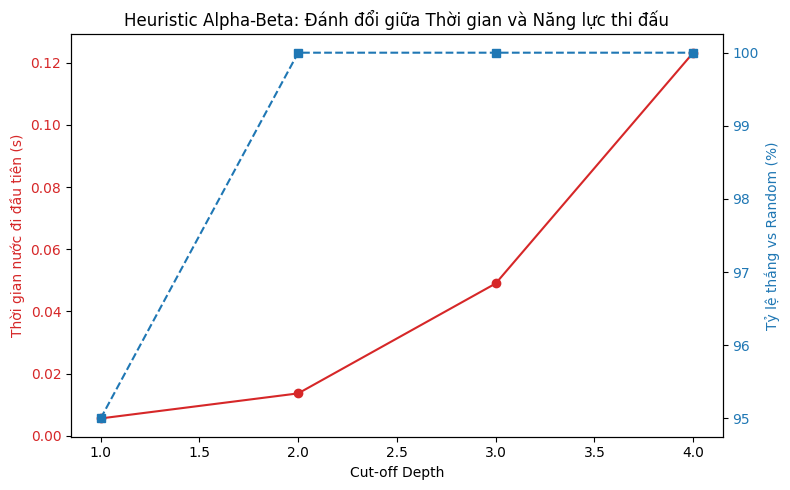

In [20]:
import time
import matplotlib.pyplot as plt

# Cấu hình thử nghiệm
depths_to_test = [1, 2, 3, 4] # Giới hạn ở 4 để thời gian chạy không quá dài trong mô phỏng
num_test_games = 20 # Số ván đấu với Tác tử Ngẫu nhiên để đo sức mạnh
alpha_beta_times = []
alpha_beta_win_rates = []

print("Đang đánh giá Heuristic Alpha-Beta Tree Search...")
for d in depths_to_test:
    agent = HeuristicMinimaxAgent(max_depth=d)

    # Đo thời gian trung bình cho 1 nước đi ở ván cờ trống (worst-case early board)
    start_t = time.time()
    agent(empty_board((6, 7)), player=1)
    avg_time = time.time() - start_t
    alpha_beta_times.append(avg_time)

    # Đo năng lực thi đấu (Win rate) bằng cách đấu với Random Agent
    wins = 0
    for _ in range(num_test_games):
        winner = play_game(agent, random_player, rows=6, cols=7)
        if winner == 1:
            wins += 1

    win_rate = (wins / num_test_games) * 100
    alpha_beta_win_rates.append(win_rate)
    print(f"Depth: {d} | Thời gian nước đầu: {avg_time:.4f}s | Tỷ lệ thắng: {win_rate}%")

# Vẽ biểu đồ
fig, ax1 = plt.subplots(figsize=(8, 5))

color = 'tab:red'
ax1.set_xlabel('Cut-off Depth')
ax1.set_ylabel('Thời gian nước đi đầu tiên (s)', color=color)
ax1.plot(depths_to_test, alpha_beta_times, marker='o', color=color, label='Thời gian')
ax1.tick_params(axis='y', labelcolor=color)

ax2 = ax1.twinx()
color = 'tab:blue'
ax2.set_ylabel('Tỷ lệ thắng vs Random (%)', color=color)
ax2.plot(depths_to_test, alpha_beta_win_rates, marker='s', color=color, linestyle='--', label='Win Rate')
ax2.tick_params(axis='y', labelcolor=color)

plt.title('Heuristic Alpha-Beta: Đánh đổi giữa Thời gian và Năng lực thi đấu')
fig.tight_layout()
plt.show()

#### Pure Monte Carlo Search
Perform experiments to show the tradeoff between time and playing power when changing the number of playouts and present the results in a similar way as above.

Đang đánh giá Pure Monte Carlo Search...
Playouts: 10 | Thời gian nước đầu: 0.8618s | Tỷ lệ thắng: 95.0%
Playouts: 50 | Thời gian nước đầu: 4.8745s | Tỷ lệ thắng: 100.0%
Playouts: 100 | Thời gian nước đầu: 8.8230s | Tỷ lệ thắng: 100.0%
Playouts: 500 | Thời gian nước đầu: 56.2402s | Tỷ lệ thắng: 100.0%


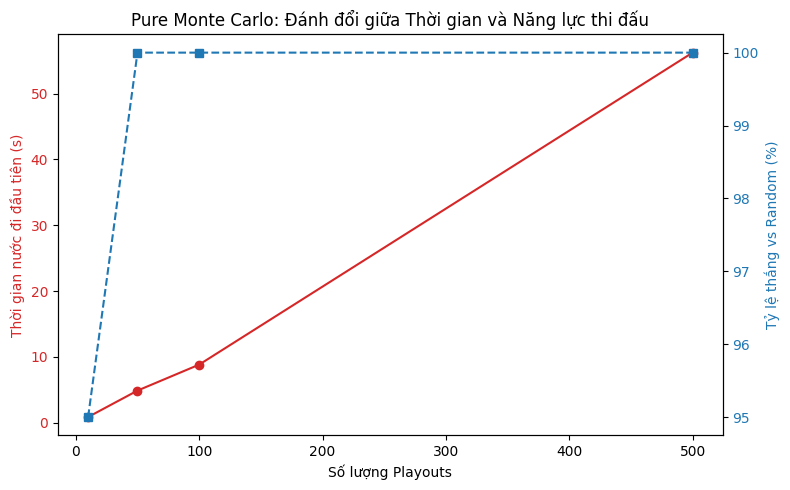

In [21]:
# Cấu hình thử nghiệm
playouts_to_test = [10, 50, 100, 500]
mc_times = []
mc_win_rates = []

print("Đang đánh giá Pure Monte Carlo Search...")
for p in playouts_to_test:
    mc_agent_test = PureMonteCarloAgent(num_playouts=p)

    # Đo thời gian trung bình cho 1 nước đi ở ván cờ trống
    start_t = time.time()
    mc_agent_test(empty_board((6, 7)), player=1)
    avg_time = time.time() - start_t
    mc_times.append(avg_time)

    # Đo năng lực thi đấu
    wins = 0
    for _ in range(num_test_games):
        winner = play_game(mc_agent_test, random_player, rows=6, cols=7)
        if winner == 1:
            wins += 1

    win_rate = (wins / num_test_games) * 100
    mc_win_rates.append(win_rate)
    print(f"Playouts: {p} | Thời gian nước đầu: {avg_time:.4f}s | Tỷ lệ thắng: {win_rate}%")

# Vẽ biểu đồ
fig, ax1 = plt.subplots(figsize=(8, 5))

color = 'tab:red'
ax1.set_xlabel('Số lượng Playouts')
ax1.set_ylabel('Thời gian nước đi đầu tiên (s)', color=color)
ax1.plot(playouts_to_test, mc_times, marker='o', color=color)
ax1.tick_params(axis='y', labelcolor=color)

ax2 = ax1.twinx()
color = 'tab:blue'
ax2.set_ylabel('Tỷ lệ thắng vs Random (%)', color=color)
ax2.plot(playouts_to_test, mc_win_rates, marker='s', color=color, linestyle='--')
ax2.tick_params(axis='y', labelcolor=color)

plt.title('Pure Monte Carlo: Đánh đổi giữa Thời gian và Năng lực thi đấu')
fig.tight_layout()
plt.show()

### Comparison

Compare the performance between the two implementations. Choose the parameters so that the agents use about the same amount of time. Present the results and discuss why you see these results.

In [22]:
minimax_competitor = HeuristicMinimaxAgent(max_depth=4)
mc_competitor = PureMonteCarloAgent(num_playouts=200)

num_compete_games = 10
results = {"Minimax_Wins": 0, "MC_Wins": 0, "Draws": 0}

print(f"Bắt đầu trận đấu kinh điển: Heuristic Minimax (Depth 4) vs Pure Monte Carlo (200 Playouts)")
for i in range(num_compete_games):
    # Luân phiên người đi trước để công bằng
    if i % 2 == 0:
        winner = play_game(minimax_competitor, mc_competitor, rows=6, cols=7)
        if winner == 1: results["Minimax_Wins"] += 1
        elif winner == -1: results["MC_Wins"] += 1
        else: results["Draws"] += 1
    else:
        winner = play_game(mc_competitor, minimax_competitor, rows=6, cols=7)
        if winner == -1: results["Minimax_Wins"] += 1
        elif winner == 1: results["MC_Wins"] += 1
        else: results["Draws"] += 1

print("\n--- KẾT QUẢ CHUNG CUỘC ---")
print(f"Heuristic Minimax thắng: {results['Minimax_Wins']}")
print(f"Pure Monte Carlo thắng: {results['MC_Wins']}")
print(f"Hòa: {results['Draws']}")

Bắt đầu trận đấu kinh điển: Heuristic Minimax (Depth 4) vs Pure Monte Carlo (200 Playouts)

--- KẾT QUẢ CHUNG CUỘC ---
Heuristic Minimax thắng: 5
Pure Monte Carlo thắng: 5
Hòa: 0
